# Testing

- Creator: Sebastian Birk (sebastian.birk@helmholtz-munich.de).
- Date of Creation: 17.05.2024
- Date of Last Modification: 12.08.2025

## 1. Setup

### 1.1 Import Libraries

In [32]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [33]:
import pickle
import re
import sys
from pathlib import Path

In [38]:
#root_path = Path.cwd()
root_path = Path('/nfs/team361/sb75/sttokbench')
src_path = root_path / "src"
sys.path.append(str(src_path))

In [39]:
src_path

PosixPath('/nfs/team361/sb75/sttokbench/src')

In [40]:
import os

import matplotlib.pyplot as plt
import scanpy as sc


from utils import collect_adata_from_folder

In [41]:
root_path = '/nfs/team361/sb75/sttokbench'
data_directory_path = f'{root_path}/data/silver'
results_directory_path = f'{root_path}/results'

In [43]:
data_directory_path

'/nfs/team361/sb75/sttokbench/data/silver'

In [45]:
adata = collect_adata_from_folder(
    load_folder_path=data_directory_path,
    cell_ids=None,
    dataset_ids=['mmb0-239b_1p', 'smb1-20b_1p'],
    obs_cols=None,
    uns_cols=None,
    include_gene_panel_size=True,
)

ValueError: No objects to concatenate

In [47]:
#warnings.filterwarnings("ignore", category=ResourceWarning)

In [51]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [52]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [58]:
sc.settings.figdir = f'{results_directory_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

## Load Token Dictionary

In [23]:
dummy_indices = []

for value in token_dict.keys():
    match = re.match(r'spv_dummy_(\d+)', str(value))
    if match:
        dummy_indices.append(int(match.group(1)))

if dummy_indices:
    lowest_index = min(dummy_indices)
    print("Lowest dummy index:", lowest_index)
else:
    print("No dummy values found.")

No dummy values found.


In [17]:
token_dictionary_file = f'{root_path}/artifacts/data/token_dictionary_mus_musculus.pkl'

# Load from disk
with open(token_dictionary_file, "rb") as file:
    token_dict = pickle.load(file)

In [28]:
token_dictionary_file

'/nfs/team361/sb75/sttokbench/artifacts/data/token_dictionary_mus_musculus.pkl'

In [24]:
len(token_dict)

25263

In [26]:
for k,v in token_dict.items():
    if 'spv' in k:
        print(k)

spv_mus_musculus
spv_brain
spv_cns
spv_merfish
spv_starmap_plus
spv_gene_panel1085
spv_gene_panel1015
spv_0_batch175
spv_0_batch194
spv_0_batch1
spv_0_batch122
spv_0_batch216
spv_0_batch11
spv_0_batch104
spv_0_batch37
spv_0_batch43
spv_0_batch6
spv_0_batch202
spv_0_batch128
spv_0_batch10
spv_0_batch179
spv_0_batch99
spv_0_batch2
spv_0_batch75
spv_0_batch5
spv_0_batch237
spv_0_batch42
spv_0_batch133
spv_0_batch211
spv_0_batch169
spv_0_batch236
spv_0_batch150
spv_0_batch28
spv_0_batch124
spv_0_batch52
spv_0_batch17
spv_0_batch205
spv_0_batch21
spv_0_batch207
spv_0_batch30
spv_0_batch58
spv_0_batch157
spv_0_batch64
spv_0_batch22
spv_0_batch91
spv_0_batch154
spv_0_batch208
spv_0_batch79
spv_0_batch65
spv_0_batch72
spv_0_batch144
spv_0_batch146
spv_0_batch38
spv_0_batch126
spv_0_batch56
spv_0_batch139
spv_0_batch8
spv_0_batch18
spv_0_batch63
spv_0_batch102
spv_0_batch120
spv_0_batch223
spv_0_batch110
spv_0_batch84
spv_0_batch32
spv_0_batch187
spv_0_batch41
spv_0_batch92
spv_0_batch86
spv_0_

In [27]:
token_dict['spv_1_batch17']

24246

AnnData object with n_obs × n_vars = 43775 × 1085
    obs: 'donor_id', 'brain_section_label', 'major_brain_region', 'ccf_region_name', 'cell_type', 'cell_id', 'n_genes'
    var: 'ensembl_id'
    uns: 'age', 'age_group', 'assay', 'batch', 'citation', 'dataset_id', 'disease_level1', 'disease_level2', 'disease_level3', 'log1p', 'sample', 'schema_reference', 'schema_version', 'sex', 'species', 'study', 'tissue', 'title'
    obsm: 'X_CCF', 'X_umap', 'spatial'


/tmp/ipykernel_2753585/924306093.py:7: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_tmp,


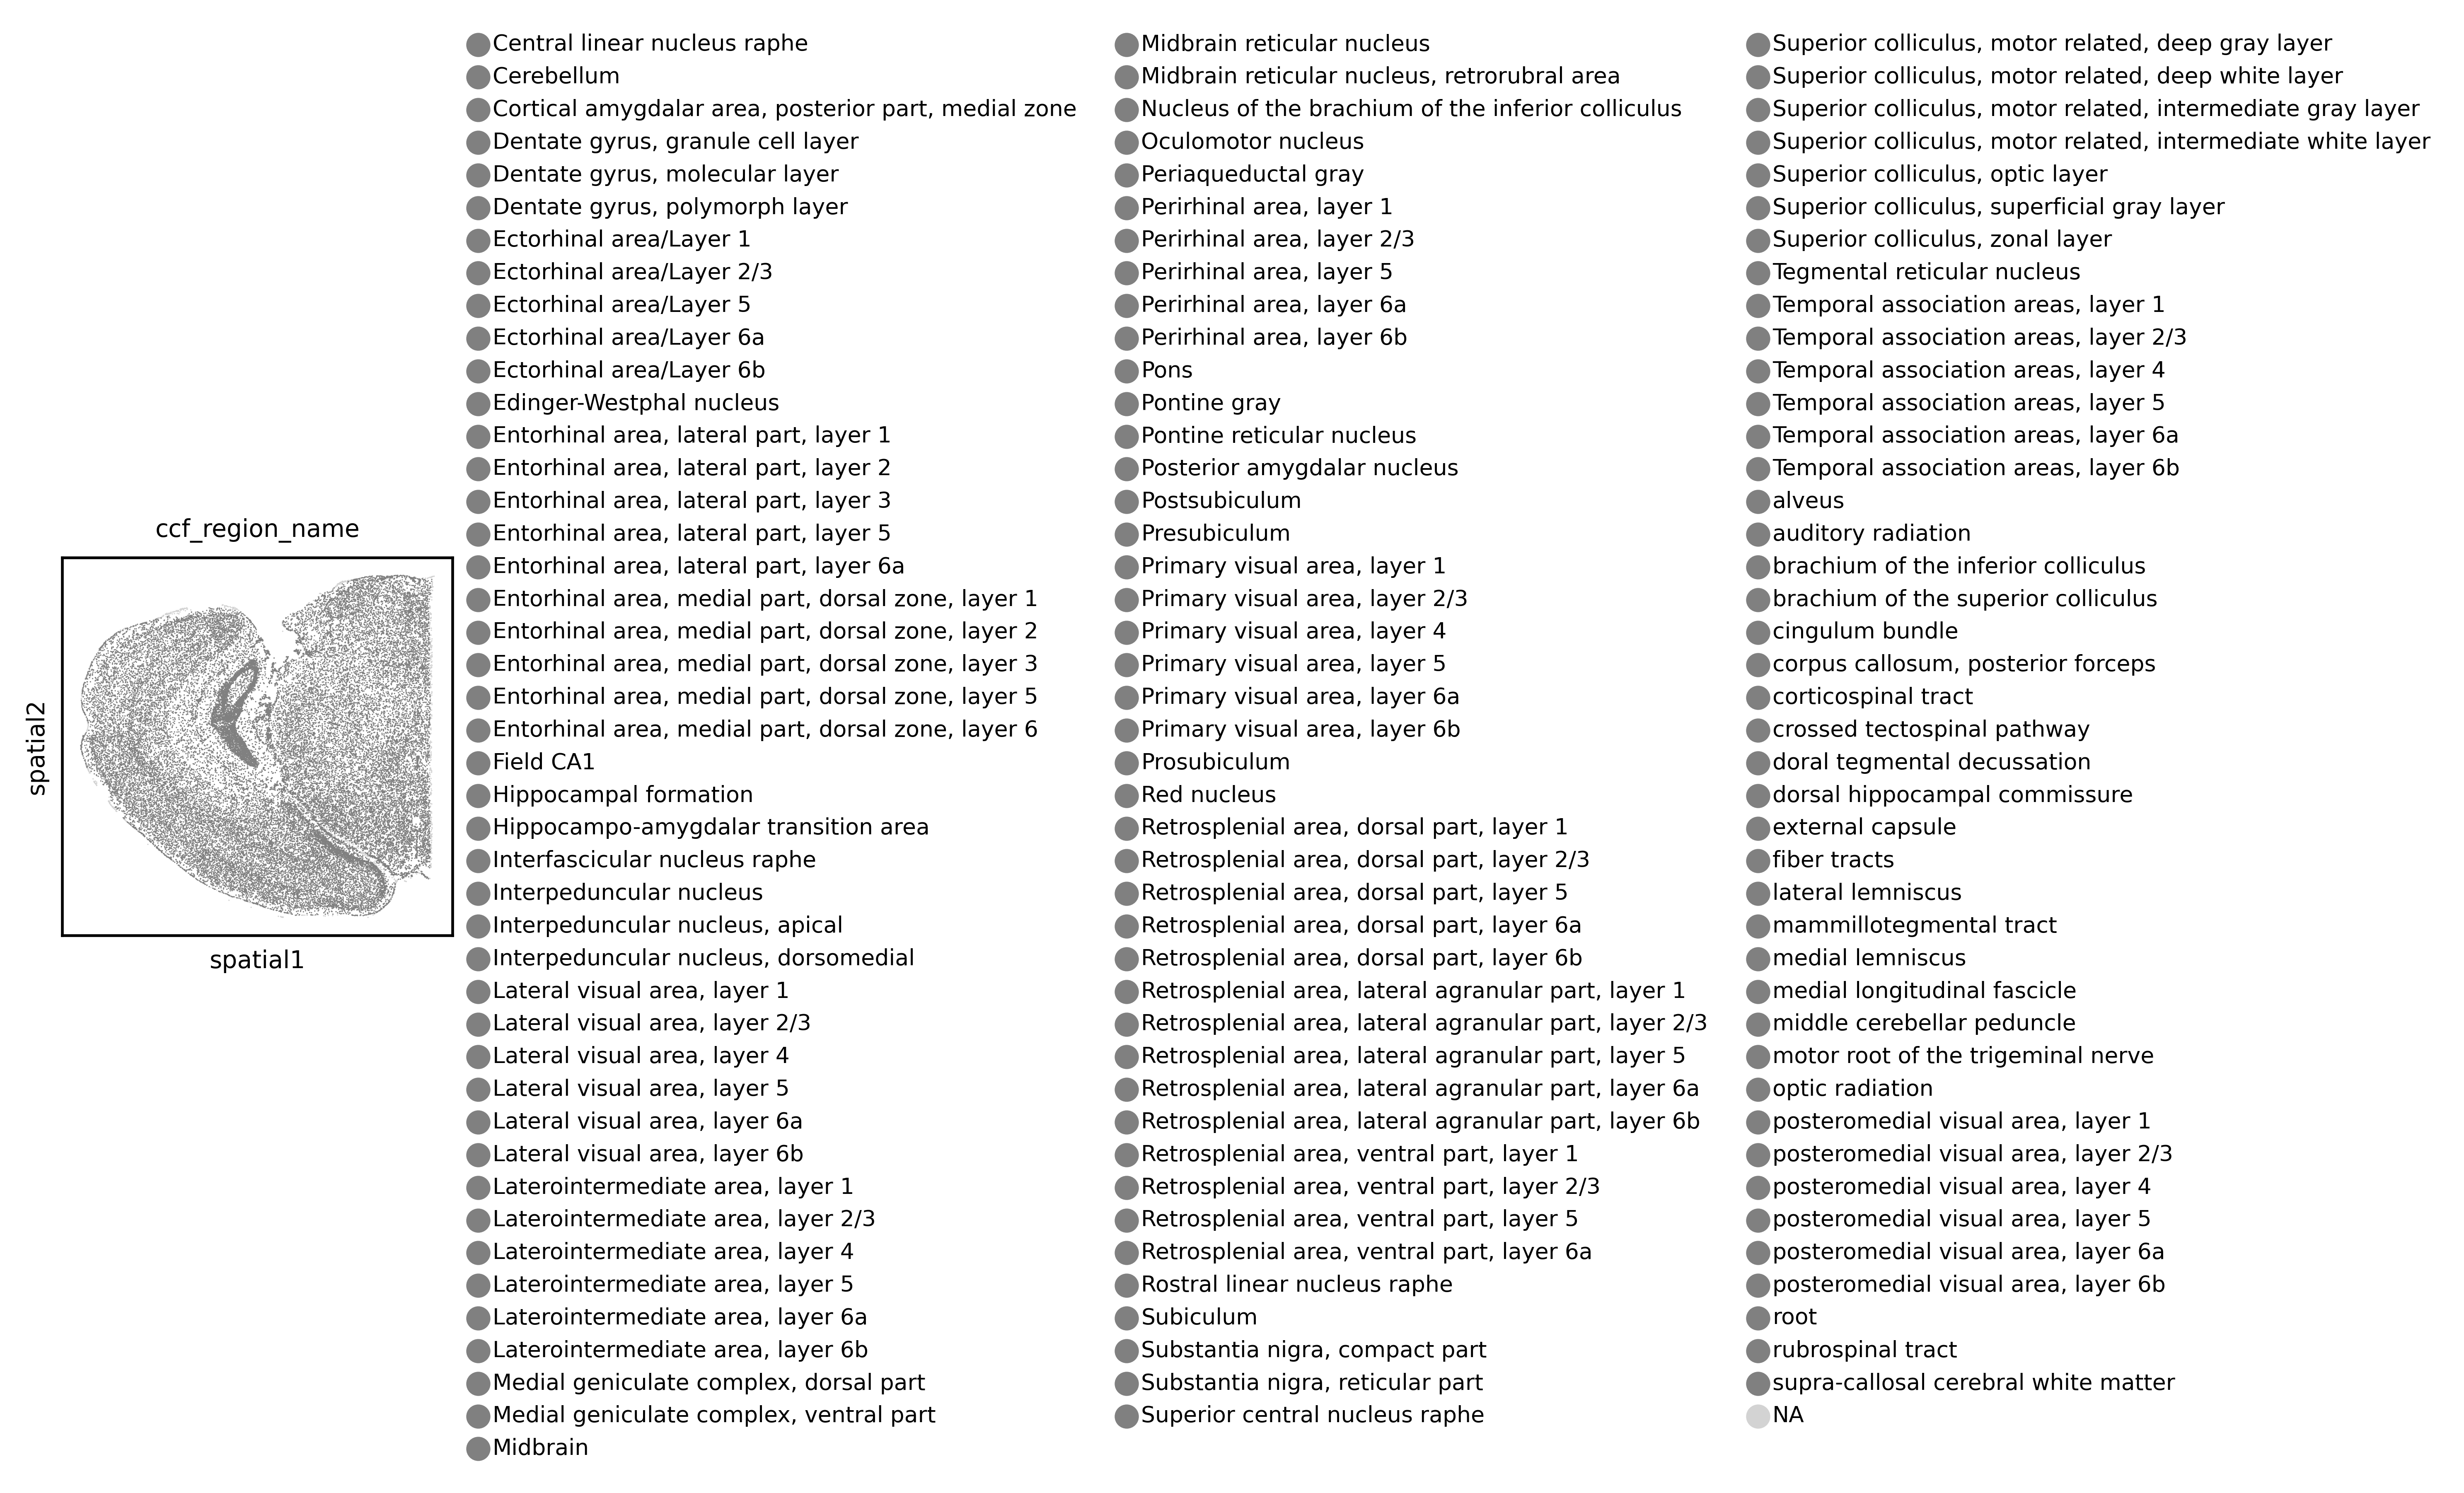

In [70]:
batch_id = 'batch100'
label = 'ccf_region_name' # 'cell_type', 'ccf_region_name', 'major_brain_region'

adata_tmp = sc.read_h5ad(f'{root_path}/data/silver/mmb0-239b_1p/harmonised_merfish_mouse_brain_239-batch_{batch_id}.h5ad')
print(adata_tmp)

sc.pl.spatial(adata_tmp,
              color=label,
              spot_size=20,
              save=f'_{batch_id}_{label}.svg')

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import os
import pickle
import warnings
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import scanpy as sc
import scipy.sparse as sp
import scgpt as scg
import seaborn as sns
import squidpy as sq
import torch
from datasets import load_from_disk
from pyensembl import EnsemblRelease
from scipy.stats import spearmanr
from scgpt.model import TransformerModel
from scgpt.tokenizer.gene_tokenizer import GeneVocab
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.preprocessing import LabelEncoder
from skmisc.loess import loess

from nichejepa import tokenizers
from nichejepa import utils
from nichejepa.models import get_1d_sincos_pos_embed_from_grid

ModuleNotFoundError: No module named 'scgpt'

In [4]:
from pyensembl import EnsemblRelease

species='homo_sapiens'
# Extract Ensembl IDs of protein coding and miRNA mouse genes
ensembl = EnsemblRelease(111, species=species)
ensembl.download()
ensembl.index()
all_genes = ensembl.genes()
protein_coding_genes = [gene for gene in all_genes if gene.biotype == "protein_coding"]
mirna_genes = [gene for gene in all_genes if gene.biotype == "miRNA"]
all_relevant_genes = protein_coding_genes + mirna_genes
gene_ids = [gene.gene_id for gene in all_relevant_genes]

INFO:pyensembl.download_cache:Fetching /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl111/Homo_sapiens.GRCh38.111.gtf.gz from URL https://ftp.ensembl.org/pub/release-111/gtf/homo_sapiens/Homo_sapiens.GRCh38.111.gtf.gz
INFO:datacache.download:Downloading https://ftp.ensembl.org/pub/release-111/gtf/homo_sapiens/Homo_sapiens.GRCh38.111.gtf.gz to /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl111/Homo_sapiens.GRCh38.111.gtf.gz
INFO:pyensembl.download_cache:Fetching /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl111/Homo_sapiens.GRCh38.cdna.all.fa.gz from URL https://ftp.ensembl.org/pub/release-111/fasta/homo_sapiens/cdna/Homo_sapiens.GRCh38.cdna.all.fa.gz
INFO:datacache.download:Downloading https://ftp.ensembl.org/pub/release-111/fasta/homo_sapiens/cdna/Homo_sapiens.GRCh38.cdna.all.fa.gz to /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl111/Homo_sapiens.GRCh38.cdna.all.fa.gz
INFO:pyensembl.download_cache:Fetching /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl

### 1.2 Run Notebook Setup

In [ ]:
warnings.filterwarnings("ignore")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

### 1.3 Configure Paths and Create Directories

In [ ]:
# Define paths
st_data_folder_path = "../../datasets/st_data" # spatially resolved transcriptomics data
st_data_bronze_folder_path = f"{st_data_folder_path}/bronze"
st_data_silver_folder_path = f"{st_data_folder_path}/silver"
st_data_gold_folder_path = f"{st_data_folder_path}/gold"
sc_data_folder_path = "../../datasets/sc_data" # spatially resolved transcriptomics data
sc_data_bronze_folder_path = f"{sc_data_folder_path}/bronze"
sc_data_silver_folder_path = f"{sc_data_folder_path}/silver"
sc_data_gold_folder_path = f"{sc_data_folder_path}/gold"
tokenizer = "cell_graph_tokenizer"
tokenizer_folder_path = f"../../datasets/tokenizer/{tokenizer}"
results_folder_path = "../../datasets/results"
geneformer_token_dictionary_file = f"../../datasets/tokenizer/geneformer_token_dictionary.pkl"
scgpt_model_dir = Path("../../artifacts/scgpt/pretrained_model")
scgpt_model_config_file = scgpt_model_dir / "args.json"
scgpt_model_file = scgpt_model_dir / "best_model.pt"
scgpt_vocab_file = scgpt_model_dir / "vocab.json"
scgpt_metadata_file = Path("../../artifacts/scgpt/metadata/gene_info.csv")

## 2. Tokenization

In [ ]:
# Define dataset
#dataset_name = "nanostring_cosmx_human_brain"
#dataset_name = "merfish_mouse_brain"
#dataset_name = "merfish_mouse_hypothalamus"
#dataset_name = "xenium_human_brain_cancer"

In [ ]:
add_cls_token = False

if dataset_name == "nanostring_cosmx_human_brain":
    n_batches = 1
    species = "homo_sapiens"
    norm_factors = ["read_depth", "cell_area", "unnormalized"]
    custom_attr_name_dict = {"cell_type": "cell_types",
                             "niche_type": "niche_types"}
    label_cats = ["cell_types", "niche_types"]
elif dataset_name == "merfish_mouse_hypothalamus":
    n_batches = 5
    species = "mus_musculus"
    norm_factors = ["prenormalized"] # already normalized by cell volume
    custom_attr_name_dict = {"cell_type": "cell_types",
                             "niche_type": "niche_types"}
    label_cats = ["cell_types", "niche_types"]
elif dataset_name == "xenium_human_brain_cancer":
    n_batches = 1
    species = "homo_sapiens"
    norm_factors = ["read_depth", "cell_area"]
    custom_attr_name_dict = {"cluster": "cluster"}
    label_cats = ["cluster"]
elif dataset_name == "merfish_mouse_brain":
    n_batches = 239
    species = "mus_musculus"
    norm_factors = ["read_depth", "unnormalized"]
    custom_attr_name_dict = {"cell_type": "cell_types",
                             "tissue": "niche_types",
                             "donor_id": "donor_id",
                             "brain_section_label": "sample_id",
                             "batch": "batch_id"}
    label_cats = ["cell_types", "niche_types"]

os.makedirs(f"{tokenizer_folder_path}/{dataset_name}", exist_ok=True)

# Set dataset-specific paths and parameters
gene_means_dictionary_file = f"{tokenizer_folder_path}/{dataset_name}/gene_means_dictionary.pkl"
gene_nzmedians_dictionary_file = f"{tokenizer_folder_path}/{dataset_name}/gene_nzmedians_dictionary.pkl"
gene_logmeans_dictionary_file = f"{tokenizer_folder_path}/{dataset_name}/gene_logmeans_dictionary.pkl"
nichejepa_token_dictionary_file = f"{tokenizer_folder_path}/{dataset_name}/token_dictionary" \
                                  f"{'_cls' if add_cls_token else '_no_cls'}.pkl"
token_dictionary_file = f"../datasets/tokenizer/token_dictionary_{species}.pkl"
input_directory = f"{st_data_silver_folder_path}/{dataset_name}"
output_directory = f"{st_data_gold_folder_path}/{tokenizer}/{dataset_name}"

### 2.1 Create Token Dictionary

In [ ]:
if species == "mus_musculus":
    # Extract Ensembl IDs of protein coding and miRNA mouse genes
    ensembl = EnsemblRelease(111, species=species)
    ensembl.download()
    ensembl.index()
    all_genes = ensembl.genes()
    protein_coding_genes = [gene for gene in all_genes if gene.biotype == "protein_coding"]
    mirna_genes = [gene for gene in all_genes if gene.biotype == "miRNA"]
    all_relevant_genes = protein_coding_genes + mirna_genes
    gene_ids = [gene.gene_id for gene in all_relevant_genes]
    
    # Create token dictionary for mouse
    token_dict = {'<pad>': 0, '<mask>': 1}
    token_dict.update({gene_id: idx + 2 for idx, gene_id in enumerate(gene_ids)})
    with open(token_dictionary_file, "wb") as f:
        pickle.dump(token_dict, f)
elif species == "homo_sapiens":
    # Load geneformer token dict to get protein-coding and miRNA genes for human
    with open(geneformer_token_dictionary_file, "rb") as f:
        token_dict = pickle.load(f)
    with open(token_dictionary_file, "wb") as f:
            pickle.dump(token_dict, f)
elif species == "sim":
    # Load data
    if n_batches == 1:
        adata = sc.read_h5ad(f"{st_data_silver_folder_path}/{dataset_name}/{dataset_name}.h5ad")
    else:
        adata = sc.read_h5ad(f"{st_data_silver_folder_path}/{dataset_name}/{dataset_name}_batch1.h5ad")

    gene_ids = adata.var["ensembl_id"]
    token_dict = {'<pad>': 0, '<mask>': 1}
    token_dict.update({gene_id: idx + 2 for idx, gene_id in enumerate(gene_ids)})
    with open(token_dictionary_file, "wb") as f:
        pickle.dump(token_dict, f)

In [ ]:
# Load data
if n_batches == 1:
    adata = sc.read_h5ad(f"{st_data_silver_folder_path}/{dataset_name}/{dataset_name}.h5ad")
else:
    adata = sc.read_h5ad(f"{st_data_silver_folder_path}/{dataset_name}/{dataset_name}_batch1.h5ad")

In [ ]:
### Create token dict for nichejepa ###
with open(token_dictionary_file, "rb") as f:
    token_dict = pickle.load(f)

# Add cls token
if add_cls_token:
    def insert_at_index(d, index, key, value):
        items = list(d.items())
        items.insert(index, (key, value))
        new_d = dict(items)
        return new_d
    token_dict = insert_at_index(token_dict, 2, "<cls>", 2)

# Remove genes not in dataset
gene_list = adata.var["ensembl_id"].tolist()
token_dict_copy = token_dict.copy()
for token in token_dict_copy.keys():
    if "ENS" in token and token not in gene_list:
        del(token_dict[token])
del(token_dict_copy)

# Separate gene tokens into cell and neighborhood tokens
new_token_dict = {
    (key if "ENS" in key else key): value
    for value, key in enumerate(token_dict.keys())}

# Write to disk
with open(nichejepa_token_dictionary_file, "wb") as file:
    pickle.dump(new_token_dict, file)

In [ ]:
# Load vocab
with open(nichejepa_token_dictionary_file, "rb") as file:
    token_dict = pickle.load(file)

token_dict_reverse = {value: key for key, value in token_dict.items()}

In [ ]:
# NicheJEPA token dict
len(token_dict)

In [ ]:
n_gene_tokens = len([token for token in token_dict.keys() if "ENS" in token])

In [ ]:
# First n tokens
n = 5
for key, value in list(token_dict.items())[:n]:
    print(f"{key}: {value}")

In [ ]:
n_gene_tokens

### 2.2 Compute Normalization Factors for Gene Counts

Corpus means, non-zero medians, or log means are used depending on the 'norm_method' specified in the CellGraphRankTokenizer (check source code).

In [ ]:
# Compute Corpus Means and Non-zero Medians for Cell and Neighborhood Genes
for norm_factor in norm_factors:
    # Load data
    if n_batches == 1:
        adata = sc.read_h5ad(f"{st_data_silver_folder_path}/{dataset_name}/{dataset_name}.h5ad")
        if type(adata.X) == sp._csr.csr_matrix:
            adata.X = adata.X.toarray()
    
        # Filter cells that did not pass QC
        if "filter_pass" in adata.obs.columns:
            filter_pass_idx = np.where([filter_pass == 1 for filter_pass in adata.obs["filter_pass"]])[0]
        else:
            print(f"adata has no column 'filter_pass'; utilizing all cells.")
            filter_pass_idx = np.array([i for i in range(adata.shape[0])])
        adata = adata[filter_pass_idx].copy()
        
        if norm_factor == "read_depth":
            # Normalize cell gene counts by read depth
            adata.X = adata.X / adata.X.sum(1).reshape(-1, 1) * 10000
        elif norm_factor == "cell_area":
            # Normalize cell gene counts by cell area
            adata.X = adata.X / adata.obs["cell_area"].values.reshape(-1, 1)
        elif norm_factor == "prenormalized":
            pass
        elif norm_factor == "unnormalized":
            pass
    else:
        adata_batch_list = []
        for batch_idx in range(1, n_batches+1):
            adata_batch = sc.read_h5ad(f"{st_data_silver_folder_path}/{dataset_name}/{dataset_name}_batch{batch_idx}.h5ad")
            if type(adata_batch.X) == sp._csr.csr_matrix:
                adata_batch.X = adata_batch.X.toarray()
            
            # Filter cells that did not pass QC
            if "filter_pass" in adata_batch.obs.columns:
                filter_pass_idx = np.where([filter_pass == 1 for filter_pass in adata_batch.obs["filter_pass"]])[0]
            else:
                print(f"adata has no column 'filter_pass'; utilizing all cells.")
                filter_pass_idx = np.array([i for i in range(adata_batch.shape[0])])
            adata_batch = adata_batch[filter_pass_idx].copy()

            if norm_factor == "read_depth":
                # Normalize cell gene counts by read depth
                adata_batch.X = adata_batch.X / adata_batch.X.sum(1).reshape(-1, 1) * 10000
            elif norm_factor == "cell_area":
                # Normalize cell gene counts by cell area
                adata_batch.X = adata_batch.X / adata_batch.obs["cell_area"].values.reshape(-1, 1)
            elif norm_factor == "prenormalized":
                pass
            elif norm_factor == "unnormalized":
                pass
                    
            adata_batch_list.append(adata_batch)
        adata = ad.concat(adata_batch_list, join="inner", axis=0)

        # Combine spatial neighborhood graphs as disconnected components
        batch_connectivities = []
        len_before_batch = 0
        for i in range(len(adata_batch_list)):
            if i == 0: # first batch
                after_batch_connectivities_extension = sp.csr_matrix(
                    (adata_batch_list[0].shape[0],
                    (adata.shape[0] -
                    adata_batch_list[0].shape[0])))
                batch_connectivities.append(sp.hstack(
                    (adata_batch_list[0].obsp["spatial_connectivities"],
                    after_batch_connectivities_extension)))
            elif i == (len(adata_batch_list) - 1): # last batch
                before_batch_connectivities_extension = sp.csr_matrix(
                    (adata_batch_list[i].shape[0],
                    (adata.shape[0] -
                    adata_batch_list[i].shape[0])))
                batch_connectivities.append(sp.hstack(
                    (before_batch_connectivities_extension,
                    adata_batch_list[i].obsp["spatial_connectivities"])))
            else: # middle batches
                before_batch_connectivities_extension = sp.csr_matrix(
                    (adata_batch_list[i].shape[0], len_before_batch))
                after_batch_connectivities_extension = sp.csr_matrix(
                    (adata_batch_list[i].shape[0],
                    (adata.shape[0] -
                    adata_batch_list[i].shape[0] -
                    len_before_batch)))
                batch_connectivities.append(sp.hstack(
                    (before_batch_connectivities_extension,
                    adata_batch_list[i].obsp["spatial_connectivities"],
                    after_batch_connectivities_extension)))
            len_before_batch += adata_batch_list[i].shape[0]
        adata.obsp["spatial_connectivities"] = sp.vstack(batch_connectivities)

        # Copy ensembl IDs
        adata.var = adata_batch_list[0].var
    
    # Compute means and non-zero medians
    gene_means = np.mean(adata.X, axis=0)
    masked_data = np.ma.masked_equal(adata.X, 0)
    gene_nzmedians = np.ma.mean(masked_data, axis=0)
    gene_nzmedians = gene_nzmedians.filled(0)

    sc.pp.log1p(adata)
    gene_logmeans = np.mean(adata.X, axis=0)

    gene_logmeans = np.array(gene_logmeans).reshape(-1)
    gene_nzmedians = np.array(gene_nzmedians).reshape(-1)
    gene_means = np.array(gene_means).reshape(-1)
 
    # Create norm factor dictionaries for tokenizer and store on disk
    gene_means_dict = {}
    gene_nzmedians_dict = {}
    gene_logmeans_dict = {}
    
    for (gene,
         gene_mean,
         gene_nzmedian,
         gene_logmean,) in zip(
            adata.var["ensembl_id"].values,
            gene_means,
            gene_nzmedians,
            gene_logmeans):
        gene_means_dict[gene] = gene_mean
        gene_nzmedians_dict[gene] = gene_nzmedian
        gene_logmeans_dict[gene] = gene_logmean
    
    with open(gene_means_dictionary_file.replace("gene", f"gene_{norm_factor}"), "wb") as file:
        pickle.dump(gene_means_dict, file)
    with open(gene_nzmedians_dictionary_file.replace("gene", f"gene_{norm_factor}"), "wb") as file:
        pickle.dump(gene_nzmedians_dict, file)
    with open(gene_logmeans_dictionary_file.replace("gene", f"gene_{norm_factor}"), "wb") as file:
        pickle.dump(gene_logmeans_dict, file)

In [ ]:
values = []
for key, value in gene_means_dict.items():
    values.append(value)

np.mean(values)

### 2.3 Run Tokenizer

In [ ]:
sq.gr.spatial_neighbors(adata,
                        coord_type="generic",
                        spatial_key="spatial",
                        radius=27.50,
                        )

max_neighbors = int(np.max(adata.obsp["spatial_connectivities"].sum(1)))

In [ ]:
# Tokenize data with different normalization methods
tokens_per_cell = n_gene_tokens # n_gene_tokens, 32

for model_input_size in [n_gene_tokens * min(16, max_neighbors) + 1,
                         # 512
                        ]:
    for norm_method in ["analytic_pearson_residuals",
                        "mean",
                        "nzmedian",
                        "seurat_v3",
                        "shifted_logmean",
                        "shifted_log",
    ]:
        if norm_method == "analytic_pearson_residuals":
            output_file_prefix = f"{dataset_name}_{norm_method}_{model_input_size}"
    
            tk = tokenizers.CellGraphRankTokenizer(
                    model_input_size=model_input_size,
                    tokens_per_cell=tokens_per_cell,
                    norm_method=norm_method,
                    gene_means_file=gene_means_dictionary_file.replace("gene", f"gene_read_depth"),
                    gene_nzmedians_file=gene_nzmedians_dictionary_file.replace("gene", f"gene_read_depth"),
                    gene_logmeans_file=gene_logmeans_dictionary_file.replace("gene", f"gene_read_depth"),
                    token_dictionary_file=nichejepa_token_dictionary_file,
                    custom_attr_name_dict=custom_attr_name_dict,
                    special_tokens = (None if not add_cls_token else ["<cls>"]),
                    special_tokens_idx = (None if not add_cls_token else [0])
            )
    
            tk.tokenize_data(input_directory=input_directory,
                             output_directory=output_directory,
                             output_file_prefix=output_file_prefix)
            
        elif norm_method != "analytic_pearson_residuals":
            for norm_factor in norm_factors:
                output_file_prefix = f"{dataset_name}_{norm_factor}_{norm_method}_{model_input_size}"
    
                tk = tokenizers.CellGraphRankTokenizer(
                        model_input_size=model_input_size,
                        tokens_per_cell=tokens_per_cell,
                        norm_method=norm_method,
                        norm_factor=norm_factor,
                        gene_means_file=gene_means_dictionary_file.replace("gene", f"gene_{norm_factor}"),
                        gene_nzmedians_file=gene_nzmedians_dictionary_file.replace("gene", f"gene_{norm_factor}"),
                        gene_logmeans_file=gene_logmeans_dictionary_file.replace("gene", f"gene_{norm_factor}"),
                        token_dictionary_file=nichejepa_token_dictionary_file,
                        custom_attr_name_dict=custom_attr_name_dict,
                        special_tokens = (None if not add_cls_token else ["<cls>"]),
                        special_tokens_idx = (None if not add_cls_token else [0])
                )
                    
                tk.tokenize_data(input_directory=input_directory,
                                 output_directory=output_directory,
                                 output_file_prefix=output_file_prefix)

### 2.4 Test Tokenizer

In [ ]:
norm_factor = norm_factors[0]
norm_method = "shifted_log"
model_input_size = n_gene_tokens * min(16, max_neighbors)
tokenized_data_folder_path = f"{st_data_gold_folder_path}/{tokenizer}/{dataset_name}/{dataset_name}_{norm_factor}_{norm_method}_{model_input_size}.dataset"
dataset = load_from_disk(tokenized_data_folder_path, keep_in_memory=True)

In [ ]:
print(dataset["gene_tokens"][0][:10])
print(dataset["cell_types"][0])
print(dataset["niche_types"][0])
print(dataset["cell_pos_tokens"][0][:10])
print(dataset["gene_pos_tokens"][0][:10])
print(dataset["input_ids"][0][:10])
print("")
idx_cell_tokens = [cell_pos_token == 0 for cell_pos_token in dataset["cell_pos_tokens"][0]].count(True)
# this is different for every cell as padding is added in the end
print(dataset["gene_tokens"][0][idx_cell_tokens:idx_cell_tokens+10])
print(dataset["cell_pos_tokens"][0][idx_cell_tokens:idx_cell_tokens+10])
print(dataset["gene_pos_tokens"][0][idx_cell_tokens:idx_cell_tokens+10])

### 2.5 Evaluate Tokenizer

#### 2.5.1 Cell Classification

In [ ]:
# Load vocab
with open(nichejepa_token_dictionary_file, "rb") as file:
    token_dict = pickle.load(file)

token_dict_reverse = {value: key for key, value in token_dict.items()}

n_gene_tokens = len([token for token in token_dict.keys() if "ENS" in token])

In [ ]:
# Get classification tokens
def get_classification_tokens(example, top_n, randomize=False):
    if randomize:
        def shuffle_nested_list_elementwise(nested_list):
            # Get the number of sublists and the length of each sublist
            num_sublists = len(nested_list)
            sublist_length = len(nested_list[0])
            
            for i in range(sublist_length):
                # Extract elements at index i from each sublist
                elements = [sublist[i] for sublist in nested_list]
                
                # Shuffle these elements
                random.shuffle(elements)
                
                # Reassign the shuffled elements back to their respective positions
                for j in range(num_sublists):
                    nested_list[j][i] = elements[j]
        
            return nested_list
    
    neighbor_cell_token_start_idx = [example["cell_pos_tokens"].index(i)
                                     for i in range(0, max(example["cell_pos_tokens"]) + 1)] # includes index cell
    neighbor_cell_token_end_idx = [
        len(example["cell_pos_tokens"]) - 1 - example["cell_pos_tokens"][::-1].index(i)
        for i in range(0, max(example["cell_pos_tokens"]) + 1)] # includes index cell

    # Get all cell tokens for each cell
    max_n_cell_tokens = len(token_dict) - 2
    example[f"top_{top_n}_neighbor_cell_token_ids"] = []
    for n in range(max_n_cell_tokens):
        neighbor_cell_token_ids = []
        for i, j in zip(neighbor_cell_token_start_idx, neighbor_cell_token_end_idx):
            if n <= (j - i):
                neighbor_cell_token_ids.append(example["gene_tokens"][i+n])
            else:
                neighbor_cell_token_ids.append(token_dict["<pad>"])
        example[f"top_{top_n}_neighbor_cell_token_ids"].append(neighbor_cell_token_ids)
        
    idx_n_cell_tokens = neighbor_cell_token_end_idx[0] - neighbor_cell_token_start_idx[0]
    index_cell_tokens = example["gene_tokens"][:idx_n_cell_tokens]

    example[f"top_{top_n}_index_cell_tokens"] = [
        token_dict_reverse[token_id]
        for token_id in index_cell_tokens]

    for n in range(max_n_cell_tokens - idx_n_cell_tokens):
        example[f"top_{top_n}_index_cell_tokens"].extend(["<pad>"])
    
    if randomize:
        random.shuffle(example[f"top_{top_n}_index_cell_tokens"])
        example[f"top_{top_n}_neighbor_cell_token_ids"] = shuffle_nested_list_elementwise(example[f"top_{top_n}_neighbor_cell_token_ids"])

    example[f"top_{top_n}_index_cell_tokens"] = example[f"top_{top_n}_index_cell_tokens"][:top_n]
    example[f"top_{top_n}_neighbor_cell_token_ids"] = example[f"top_{top_n}_neighbor_cell_token_ids"][:top_n]

    example[f"top_{top_n}_neighbor_cell_tokens"] = [[
        token_dict_reverse[token_id]
        for token_id in neighbor_cell_tokens]
        for neighbor_cell_tokens in example[f"top_{top_n}_neighbor_cell_token_ids"]]

    return example

In [ ]:
# Test classification token retrieval
top_n = 10
model_input_size = n_gene_tokens * min(16, max_neighbors) # 512

norm_method = "shifted_log"
norm_factor = "read_depth" # "read_depth", "cell_area"
normalization = f"{norm_factor}_{norm_method}"
    
output_file_prefix = f"{dataset_name}_{normalization}_{model_input_size}"
tokenized_data_folder_path = f"{st_data_gold_folder_path}/{tokenizer}/{dataset_name}/{output_file_prefix}.dataset"
dataset = load_from_disk(tokenized_data_folder_path, keep_in_memory=True)
dataset = dataset.map(get_classification_tokens,
                      fn_kwargs={"top_n": top_n},
                      #cache_file_name=dataset_cache_file,
                     )

print(dataset[f"top_{top_n}_neighbor_cell_tokens"][0])
print("")
print(dataset[f"top_{top_n}_index_cell_tokens"][0])
print("")

top_n = n_gene_tokens
dataset = dataset.map(get_classification_tokens,
                      fn_kwargs={"top_n": top_n},
                      #cache_file_name=dataset_cache_file,
                     )

print(dataset[f"top_{top_n}_neighbor_cell_tokens"][0])
print("")
print(dataset[f"top_{top_n}_index_cell_tokens"][0])
print("")

##### 2.5.1.1 Baseline (Random Gene Embeddings)

Task: cell and niche type classification using randomly embedded top ranked genes.

In [ ]:
emsemblid_embedding_mapping = {}
for key in token_dict.keys():
   emsemblid_embedding_mapping[key] = np.random.randn(512)

In [ ]:
mode = "nopos"
top_n = 10 # n_gene_tokens, 30, 10

randomize = True # True, False
if randomize:
    random.seed(42)
    model_input_size = n_gene_tokens * min(16, max_neighbors) 
else:
    if top_n == n_gene_tokens:
        model_input_size = n_gene_tokens * min(16, max_neighbors) 
    else:
        model_input_size = n_gene_tokens * min(16, max_neighbors) # 512

scores = []

os.makedirs(f"{results_folder_path}/{tokenizer}/{dataset_name}", exist_ok=True)

for norm_method in ["analytic_pearson_residuals",
                    "mean",
                    "nzmedian",
                    "seurat_v3",
                    "shifted_logmean",
                    "shifted_log"
                   ]:
    for norm_factor in norm_factors:
        if norm_method == "analytic_pearson_residuals":
            normalization = f"{norm_method}"
            if norm_factor != "read_depth":
                continue
        if norm_method != "analytic_pearson_residuals":
            normalization = f"{norm_factor}_{norm_method}"
    
        output_file_prefix = f"{dataset_name}_{normalization}_{model_input_size}"
        tokenized_data_folder_path = f"{st_data_gold_folder_path}/{tokenizer}/{dataset_name}/{output_file_prefix}.dataset"
        dataset = load_from_disk(tokenized_data_folder_path, keep_in_memory=True)
        
        dataset = dataset.map(get_classification_tokens,
                              fn_kwargs={"top_n": top_n, "randomize": randomize},
                              #cache_file_name=dataset_cache_file,
                             )
    
        X_cell = np.array(
            [[emsemblid_embedding_mapping.get(token, np.random.randn(512)) for token in sequence] for
             sequence in dataset[f"top_{top_n}_index_cell_tokens"]])
        X_cell = np.mean(X_cell, axis=1) # aggregate across tokens
        X_cell = X_cell.reshape(X_cell.shape[0], -1)
    
        X_neighbor_cells = np.array(
            [[np.mean([emsemblid_embedding_mapping.get(token, np.random.randn(512)) for token in neighbor_cell_tokens], axis=0) for
              neighbor_cell_tokens in sequence] for sequence in dataset[f"top_{top_n}_neighbor_cell_tokens"]])
        X_neighbor_cells = np.mean(X_neighbor_cells, axis=1) # aggregate across tokens
        X_neighbor_cells = X_neighbor_cells.reshape(X_neighbor_cells.shape[0], -1)
    
        for token_type in ["cell", "neighbor_cells"]:
            for label_cat in label_cats:
                label_encoder = LabelEncoder()
                labels = np.array(
                    label_encoder.fit_transform(dataset[label_cat]))
    
                for random_state in range(10):
    
                    np.random.seed(random_state)
        
                    indices = np.arange(X_cell.shape[0])
                    np.random.shuffle(indices)
                    num_train = int(0.8 * len(indices))
                    train_indices = indices[:num_train]
                    test_indices = indices[num_train:]
                    labels_train = labels[train_indices]
                    labels_test = labels[test_indices]
                    if token_type == "cell":
                        X = X_cell
                    else:
                        X = X_neighbor_cells
                    X_train = X[train_indices]
                    X_test = X[test_indices]
                
                    lr_clf = LogisticRegression()
                    lr_clf.fit(X_train, labels_train)
                    train_predictions = lr_clf.predict(X_train)
                    train_f1 = f1_score(labels_train, train_predictions, average="weighted")
                    train_score = lr_clf.score(X_train, labels_train)
                    test_predictions = lr_clf.predict(X_test)
                    test_f1 = f1_score(labels_test, test_predictions, average="weighted")
                    test_score = lr_clf.score(X_test, labels_test)
                    scores.append({"tokenizer": tokenizer,
                                   "normalization": normalization,
                                   "token_type": token_type,
                                   "clf_task": label_cat,
                                   "random_state": random_state,
                                   "clf_category": "train",
                                   "f1_score": train_f1,
                                   "accuracy": train_score})
                    scores.append({"tokenizer": tokenizer,
                                   "normalization": normalization,
                                   "token_type": token_type,
                                   "clf_task": label_cat,
                                   "random_state": random_state,
                                   "clf_category": "test",
                                   "f1_score": test_f1,
                                   "accuracy": test_score})
    
                    scores_df = pd.DataFrame(scores)
                    scores_df.to_csv(f"""{results_folder_path}/{tokenizer}/{dataset_name}/clf_scores_baseline_top{top_n}_{mode}{'_randomized' if randomize else ''}.csv""", index=False)

##### 2.5.1.2 Baseline (Random Gene Embeddings & Random Positional Embeddings)

In [ ]:
pos_embedding_mapping = {}
for key in range(n_gene_tokens):
   pos_embedding_mapping[key] = np.random.randn(512)

In [ ]:
mode = "randpos"
top_n = 10 # n_gene_tokens, 30, 10

if top_n == n_gene_tokens:
    model_input_size = n_gene_tokens * min(16, max_neighbors)
else:
    model_input_size = n_gene_tokens * min(16, max_neighbors) # 512

os.makedirs(f"{results_folder_path}/{tokenizer}/{dataset_name}", exist_ok=True)

for norm_method in ["analytic_pearson_residuals",
                    "mean",
                    "nzmedian",
                    "seurat_v3",
                    "shifted_logmean",
                    "shifted_log"
                   ]:
    for norm_factor in norm_factors:
        if norm_method == "analytic_pearson_residuals":
            normalization = f"{norm_method}"
            if norm_factor != "read_depth":
                continue
        if norm_method != "analytic_pearson_residuals":
            normalization = f"{norm_factor}_{norm_method}"
    
        output_file_prefix = f"{dataset_name}_{normalization}_{model_input_size}"
        tokenized_data_folder_path = f"{st_data_gold_folder_path}/{tokenizer}/{dataset_name}/{output_file_prefix}.dataset"
        dataset = load_from_disk(tokenized_data_folder_path, keep_in_memory=True)

        top_n = 10
        
        dataset = dataset.map(get_classification_tokens,
                              fn_kwargs={"top_n": top_n},
                              #cache_file_name=dataset_cache_file,
                             )
    
        X_cell = np.array(
            [[emsemblid_embedding_mapping.get(token, np.random.randn(512)) +
              pos_embedding_mapping[i] for i, token in enumerate(sequence)] for
             sequence in dataset[f"top_{top_n}_index_cell_tokens"]])
        X_cell = np.mean(X_cell, axis=1) # aggregate across tokens
        X_cell = X_cell.reshape(X_cell.shape[0], -1)
    
        X_neighbor_cells = np.array(
            [[np.mean([emsemblid_embedding_mapping.get(token, np.random.randn(512))  +
              pos_embedding_mapping[i] for i, token in enumerate(neighbor_cell_tokens)], axis=0) for
              neighbor_cell_tokens in sequence] for sequence in dataset[f"top_{top_n}_neighbor_cell_tokens"]])
        X_neighbor_cells = np.mean(X_neighbor_cells, axis=1) # aggregate across tokens
        X_neighbor_cells = X_neighbor_cells.reshape(X_neighbor_cells.shape[0], -1)
    
        for token_type in ["cell", "neighbor_cells"]:
            for label_cat in label_cats:
                label_encoder = LabelEncoder()
                labels = np.array(
                    label_encoder.fit_transform(dataset[label_cat]))
    
                for random_state in range(10):
    
                    np.random.seed(random_state)
        
                    indices = np.arange(X_cell.shape[0])
                    np.random.shuffle(indices)
                    num_train = int(0.8 * len(indices))
                    train_indices = indices[:num_train]
                    test_indices = indices[num_train:]
                    labels_train = labels[train_indices]
                    labels_test = labels[test_indices]
                    if token_type == "cell":
                        X = X_cell
                    else:
                        X = X_neighbor_cells
                    X_train = X[train_indices]
                    X_test = X[test_indices]
                
                    lr_clf = LogisticRegression()
                    lr_clf.fit(X_train, labels_train)
                    train_predictions = lr_clf.predict(X_train)
                    train_f1 = f1_score(labels_train, train_predictions, average="weighted")
                    train_score = lr_clf.score(X_train, labels_train)
                    test_predictions = lr_clf.predict(X_test)
                    test_f1 = f1_score(labels_test, test_predictions, average="weighted")
                    test_score = lr_clf.score(X_test, labels_test)
                    scores.append({"tokenizer": tokenizer,
                                   "normalization": normalization,
                                   "token_type": token_type,
                                   "clf_task": label_cat,
                                   "random_state": random_state,
                                   "clf_category": "train",
                                   "f1_score": train_f1,
                                   "accuracy": train_score})
                    scores.append({"tokenizer": tokenizer,
                                   "normalization": normalization,
                                   "token_type": token_type,
                                   "clf_task": label_cat,
                                   "random_state": random_state,
                                   "clf_category": "test",
                                   "f1_score": test_f1,
                                   "accuracy": test_score})
    
                    scores_df = pd.DataFrame(scores)
                    scores_df.to_csv(f"{results_folder_path}/{tokenizer}/{dataset_name}/clf_scores_baseline_top{top_n}_{mode}.csv", index=False)

##### 2.5.1.3 Baseline (Random Gene Embeddings & Sinusoidal Positional Embeddings)

In [ ]:
pos_embed = get_1d_sincos_pos_embed_from_grid(
    512,
    np.arange(n_gene_tokens))

pos_embedding_mapping = {}
for key in range(n_gene_tokens):
   pos_embedding_mapping[key] = pos_embed[key]

In [ ]:
mode = "sinpos"
top_n = 10 # n_gene_tokens, 30, 10

if top_n == n_gene_tokens:
    model_input_size = n_gene_tokens * min(16, max_neighbors)
else:
    model_input_size = n_gene_tokens * min(16, max_neighbors) # 512

scores = []

os.makedirs(f"{results_folder_path}/{tokenizer}/{dataset_name}", exist_ok=True)

for norm_method in ["analytic_pearson_residuals",
                    "mean",
                    "nzmedian",
                    "seurat_v3",
                    "shifted_logmean",
                    "shifted_log"
                   ]:
    for norm_factor in norm_factors:
        if norm_method == "analytic_pearson_residuals":
            normalization = f"{norm_method}"
            if norm_factor != "read_depth":
                continue
        if norm_method != "analytic_pearson_residuals":
            normalization = f"{norm_factor}_{norm_method}"
    
        output_file_prefix = f"{dataset_name}_{normalization}_{model_input_size}"
        tokenized_data_folder_path = f"{st_data_gold_folder_path}/{tokenizer}/{dataset_name}/{output_file_prefix}.dataset"
        dataset = load_from_disk(tokenized_data_folder_path, keep_in_memory=True)

        top_n = 10
        
        dataset = dataset.map(get_classification_tokens,
                              fn_kwargs={"top_n": top_n},
                              #cache_file_name=dataset_cache_file,
                             )
    
        X_cell = np.array(
            [[emsemblid_embedding_mapping.get(token, np.random.randn(512)) +
              pos_embedding_mapping[i] for i, token in enumerate(sequence)] for
             sequence in dataset[f"top_{top_n}_index_cell_tokens"]])
        X_cell = np.mean(X_cell, axis=1) # aggregate across tokens
        X_cell = X_cell.reshape(X_cell.shape[0], -1)
    
        X_neighbor_cells = np.array(
            [[np.mean([emsemblid_embedding_mapping.get(token, np.random.randn(512))  +
              pos_embedding_mapping[i] for i, token in enumerate(neighbor_cell_tokens)], axis=0) for
              neighbor_cell_tokens in sequence] for sequence in dataset[f"top_{top_n}_neighbor_cell_tokens"]])
        X_neighbor_cells = np.mean(X_neighbor_cells, axis=1) # aggregate across tokens
        X_neighbor_cells = X_neighbor_cells.reshape(X_neighbor_cells.shape[0], -1)
    
        for token_type in ["cell", "neighbor_cells"]:
            for label_cat in label_cats:
                label_encoder = LabelEncoder()
                labels = np.array(
                    label_encoder.fit_transform(dataset[label_cat]))
    
                for random_state in range(10):
    
                    np.random.seed(random_state)
        
                    indices = np.arange(X_cell.shape[0])
                    np.random.shuffle(indices)
                    num_train = int(0.8 * len(indices))
                    train_indices = indices[:num_train]
                    test_indices = indices[num_train:]
                    labels_train = labels[train_indices]
                    labels_test = labels[test_indices]
                    if token_type == "cell":
                        X = X_cell
                    else:
                        X = X_neighbor_cells
                    X_train = X[train_indices]
                    X_test = X[test_indices]
                
                    lr_clf = LogisticRegression()
                    lr_clf.fit(X_train, labels_train)
                    train_predictions = lr_clf.predict(X_train)
                    train_f1 = f1_score(labels_train, train_predictions, average="weighted")
                    train_score = lr_clf.score(X_train, labels_train)
                    test_predictions = lr_clf.predict(X_test)
                    test_f1 = f1_score(labels_test, test_predictions, average="weighted")
                    test_score = lr_clf.score(X_test, labels_test)
                    scores.append({"tokenizer": tokenizer,
                                   "normalization": normalization,
                                   "token_type": token_type,
                                   "clf_task": label_cat,
                                   "random_state": random_state,
                                   "clf_category": "train",
                                   "f1_score": train_f1,
                                   "accuracy": train_score})
                    scores.append({"tokenizer": tokenizer,
                                   "normalization": normalization,
                                   "token_type": token_type,
                                   "clf_task": label_cat,
                                   "random_state": random_state,
                                   "clf_category": "test",
                                   "f1_score": test_f1,
                                   "accuracy": test_score})
    
                    scores_df = pd.DataFrame(scores)
                    scores_df.to_csv(f"{results_folder_path}/{tokenizer}/{dataset_name}/clf_scores_baseline_top{top_n}_{mode}.csv", index=False)

##### 2.5.1.4 scGPT

Task: cell and niche type classification using scGPT embedded top ranked genes.

In [ ]:
if "sim" not in dataset_name:
    ### Get scGPT gene embeddings for each gene Ensembl id ###
    
    # Set config
    pad_token = "<pad>"
    special_tokens = [pad_token, "<cls>", "<eoc>"]
    pad_value = -2
    n_input_bins = 51
    
    # Get vocab
    scgpt_vocab = GeneVocab.from_file(scgpt_vocab_file)
    for s in special_tokens:
        if s not in scgpt_vocab:
            scgpt_vocab.append_token(s)
    
    # Retrieve model parameters from config files
    with open(scgpt_model_config_file, "r") as f:
        model_configs = json.load(f)
    print(f"Resume model from {scgpt_model_file}, the model args will override the "
          f"config {scgpt_model_config_file}.")
    embsize = model_configs["embsize"]
    nhead = model_configs["nheads"]
    d_hid = model_configs["d_hid"]
    nlayers = model_configs["nlayers"]
    n_layers_cls = model_configs["n_layers_cls"]
    
    # Initialize model
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    ntokens = len(scgpt_vocab)  # size of vocabulary
    model = TransformerModel(ntokens,
                             embsize,
                             nhead,
                             d_hid,
                             nlayers,
                             vocab=scgpt_vocab,
                             pad_value=pad_value,
                             n_input_bins=n_input_bins,)
    
    try:
        model.load_state_dict(torch.load(scgpt_model_file))
        print(f"Loading all model params from {scgpt_model_file}")
    except:
        model_dict = model.state_dict()
        pretrained_dict = torch.load(scgpt_model_file)
        pretrained_dict = {k: v
                           for k, v in pretrained_dict.items()
                           if k in model_dict and v.shape == model_dict[k].shape}
        for k, v in pretrained_dict.items():
            print(f"Loading params {k} with shape {v.shape}")
            model_dict.update(pretrained_dict)
            model.load_state_dict(model_dict)
    model.to(device)
    
    # Create mapping from Ensembl id to scGPT token id
    gene2idx = scgpt_vocab.get_stoi()
    
    metadata_df = pd.read_csv(scgpt_metadata_file)
    
    ensemblid_mapping = dict(zip(metadata_df["feature_name"], metadata_df["feature_id"]))
    ensemblid2idx = {ensemblid_mapping[k]: v for k, v in gene2idx.items() if k in ensemblid_mapping}
    
    # Retrieve the data-independent gene embeddings from scGPT
    gene_ids = np.array([id for id in ensemblid2idx.values()])
    gene_embeddings = model.encoder(torch.tensor(gene_ids, dtype=torch.long).to(device))
    gene_embeddings = gene_embeddings.detach().cpu().numpy()
    
    # Store gene embeddings with Ensembl id
    emsemblid_embedding_mapping = {}
    for i, (key, val) in enumerate(ensemblid2idx.items()):
        emsemblid_embedding_mapping[key] = gene_embeddings[i, :]

In [ ]:
if "sim" not in dataset_name:
    # Test scGPT embedding retrieval
    X_cell = np.array(
        [[emsemblid_embedding_mapping[token] for token in sequence] for
         sequence in dataset[f"top_{top_n}_index_cell_tokens"]])
    X_cell = X_cell.reshape(X_cell.shape[0], -1)
    
    X_neighbor_cells = np.array(
        [[np.mean([emsemblid_embedding_mapping[token] for token in neighbor_cell_tokens], axis=0) for
          neighbor_cell_tokens in sequence] for sequence in dataset[f"top_{top_n}_neighbor_cell_tokens"]])
    X_neighbor_cells = X_neighbor_cells.reshape(X_neighbor_cells.shape[0], -1)
    
    print(X_cell)

In [ ]:
if "sim" not in dataset_name:
    top_n = 10 # n_gene_tokens, 30, 10

    if top_n == n_gene_tokens:
        model_input_size = n_gene_tokens * min(16, max_neighbors)
    else:
        model_input_size = 512    

    scores = []
    
    os.makedirs(f"{results_folder_path}/{tokenizer}/{dataset_name}", exist_ok=True)
    
    for norm_method in ["analytic_pearson_residuals",
                        "mean",
                        "nzmedian",
                        "seurat_v3",
                        "shifted_logmean",
                        "shifted_log"
                       ]:
        for norm_factor in norm_factors:
            if norm_method == "analytic_pearson_residuals":
                normalization = f"{norm_method}"
                if norm_factor == "cell_area":
                    continue
            if norm_method != "analytic_pearson_residuals":
                normalization = f"{norm_factor}_{norm_method}"
        
            output_file_prefix = f"{dataset_name}_{normalization}_{model_input_size}"
            tokenized_data_folder_path = f"{st_data_gold_folder_path}/{tokenizer}/{dataset_name}/{output_file_prefix}.dataset"
            dataset = load_from_disk(tokenized_data_folder_path, keep_in_memory=True)
            
            dataset = dataset.map(get_classification_tokens,
                                  fn_kwargs={"top_n": top_n},
                                  #cache_file_name=dataset_cache_file,
                                 )
        
            X_cell = np.array(
                [[emsemblid_embedding_mapping.get(token, np.random.randn(512)) for token in sequence] for
                 sequence in dataset[f"top_{top_n}_index_cell_tokens"]])
            X_cell = np.mean(X_cell, axis=1) # aggregate across tokens
            X_cell = X_cell.reshape(X_cell.shape[0], -1)
        
            X_neighbor_cells = np.array(
                [[np.mean([emsemblid_embedding_mapping.get(token, np.random.randn(512)) for token in neighbor_cell_tokens], axis=0) for
                  neighbor_cell_tokens in sequence] for sequence in dataset[f"top_{top_n}_neighbor_cell_tokens"]])
            X_neighbor_cells = np.mean(X_neighbor_cells, axis=1) # aggregate across tokens
            X_neighbor_cells = X_neighbor_cells.reshape(X_neighbor_cells.shape[0], -1)
        
            for token_type in ["cell", "neighbor_cells"]:
                for label_cat in label_cats:
                    label_encoder = LabelEncoder()
                    labels = np.array(
                        label_encoder.fit_transform(dataset[label_cat]))
        
                    for random_state in range(10):
        
                        np.random.seed(random_state)
            
                        indices = np.arange(X_cell.shape[0])
                        np.random.shuffle(indices)
                        num_train = int(0.8 * len(indices))
                        train_indices = indices[:num_train]
                        test_indices = indices[num_train:]
                        labels_train = labels[train_indices]
                        labels_test = labels[test_indices]
                        if token_type == "cell":
                            X = X_cell
                        else:
                            X = X_neighbor_cells
                        X_train = X[train_indices]
                        X_test = X[test_indices]
                    
                        lr_clf = LogisticRegression()
                        lr_clf.fit(X_train, labels_train)
                        train_predictions = lr_clf.predict(X_train)
                        train_f1 = f1_score(labels_train, train_predictions, average="weighted")
                        train_score = lr_clf.score(X_train, labels_train)
                        test_predictions = lr_clf.predict(X_test)
                        test_f1 = f1_score(labels_test, test_predictions, average="weighted")
                        test_score = lr_clf.score(X_test, labels_test)
                        scores.append({"tokenizer": tokenizer,
                                       "normalization": normalization,
                                       "token_type": token_type,
                                       "clf_task": label_cat,
                                       "random_state": random_state,
                                       "clf_category": "train",
                                       "f1_score": train_f1,
                                       "accuracy": train_score})
                        scores.append({"tokenizer": tokenizer,
                                       "normalization": normalization,
                                       "token_type": token_type,
                                       "clf_task": label_cat,
                                       "random_state": random_state,
                                       "clf_category": "test",
                                       "f1_score": test_f1,
                                       "accuracy": test_score})
        
                        scores_df = pd.DataFrame(scores)
                        scores_df.to_csv(f"{results_folder_path}/{tokenizer}/{dataset_name}/clf_scores_scgpt_top(top_n).csv", index=False)

### 2.6 Miscellaneous

In [ ]:
### Consolodidate all metrics into one file ###

# Define the folder containing CSV files
folder_path = "../datasets/results/cell_graph_tokenizer/nanostring_cosmx_human_brain"

# List all CSV files in the folder
csv_files = [f for f in os.listdir(folder_path) if "clf_scores" in f and f.endswith('.csv')]

# Initialize an empty list to hold DataFrames
dataframes = []

# Load each CSV file into a DataFrame and append to the list
for file in csv_files:
    file_path = os.path.join(folder_path, file)
    df = pd.read_csv(file_path)
    dataframes.append(df)

# Concatenate all DataFrames vertically
combined_df = pd.concat(dataframes, ignore_index=True)

# Define the order of categories for each column
category_order_col1 = ['analytic_pearson_residuals',
                       'read_depth_mean',
                       'read_depth_nzmedian',
                       'read_depth_seurat_v3',
                       "read_depth_shifted_logmean",
                       "read_depth_shifted_log",
                       "cell_area_mean",
                       "cell_area_nzmedian",
                       "cell_area_seurat_v3",
                       "cell_area_shifted_logmean",
                       "cell_area_shifted_log"]  # Example order for column 1
category_order_col2 = ['cell', 'neighborhood']            # Example order for column 2
category_order_col3 = ['cell_types', 'niche_types']     # Example order for column 3

# Convert columns to categorical with defined order
combined_df['normalization'] = pd.Categorical(combined_df['normalization'], categories=category_order_col1, ordered=True)
combined_df['token_type'] = pd.Categorical(combined_df['token_type'], categories=category_order_col2, ordered=True)
combined_df['clf_task'] = pd.Categorical(combined_df['clf_task'], categories=category_order_col3, ordered=True)

# Sort the DataFrame by the three columns
sorted_df = combined_df.sort_values(by=['normalization', 'token_type', 'clf_task', "random_state"])
sorted_df.reset_index(inplace=True, drop=True)
unique_df = sorted_df.drop_duplicates(subset=['normalization', 'token_type', 'clf_task', 'random_state', 'clf_category'])
unique_df.reset_index(inplace=True, drop=True)

# Display the DataFrame
display(unique_df)

unique_df.to_csv(f"{results_folder_path}/{tokenizer}/{dataset_name}/clf_scores_scgpt.csv", index=False)

In [ ]:
print(np.var([2, 4, 8]))
print(np.var([20, 40, 80]))
print(np.var([2, 4, 8] - np.array([np.mean([2, 20]), np.mean([4, 40]), np.mean([8, 80])])))
print(np.var([20, 40, 80] - np.array([np.mean([2, 20]), np.mean([4, 40]), np.mean([8, 80])])))

In [ ]:
print(np.var(np.log([2, 4, 8])))
print(np.var(np.log([20, 40, 80])))
print(np.var(np.log([2, 4, 8]) - np.array([np.mean(np.log([2, 20])), np.mean(np.log([4, 40])), np.mean(np.log([8, 80]))])))
print(np.var(np.log([20, 40, 80]) - np.array([np.mean(np.log([2, 20])), np.mean(np.log([4, 40])), np.mean(np.log([8, 80]))])))

In [ ]:
print(np.var(np.log([2, 4, 8])))
print(np.var(np.log([20, 40, 80])))
print(np.var(np.log([2, 4, 8]) / np.array([np.mean(np.log([2, 20])), np.mean(np.log([4, 40])), np.mean(np.log([8, 80]))])))
print(np.var(np.log([20, 40, 80]) / np.array([np.mean(np.log([2, 20])), np.mean(np.log([4, 40])), np.mean(np.log([8, 80]))])))

In [ ]:
i = 12
# Get sorted indices of neighbor cells based on distance to index cell
row_start = adata.obsp["spatial_distances"].indptr[i]
row_end = adata.obsp["spatial_distances"].indptr[i+1]
row_data = adata.obsp["spatial_distances"].data[row_start:row_end]
sorted_indices = np.argsort(row_data)
row_data

adata.obsp["spatial_connectivities"][i].nonzero()[1][sorted_indices][0]
adata.obsp["spatial_connectivities"][i].nonzero()[1]
dataset["gene_tokens"][i][64:]
dataset["gene_tokens"][adata.obsp["spatial_connectivities"][i].nonzero()[1][sorted_indices][0]]

In [ ]:
tk = tokenizers.CellGraphRankTokenizer(
        model_input_size=model_input_size,
        norm_method=norm_method,
        gene_means_file=gene_means_dictionary_file.replace("gene", f"gene_{norm_factor}"),
        gene_reg_stds_file=gene_reg_stds_dictionary_file.replace("gene", f"gene_{norm_factor}"),
        gene_nzmedians_file=gene_nzmedians_dictionary_file.replace("gene", f"gene_{norm_factor}"),
        gene_logmeans_file=gene_logmeans_dictionary_file.replace("gene", f"gene_{norm_factor}"),
        token_dictionary_file=nichejepa_token_dictionary_file,
        custom_attr_name_dict=custom_attr_name_dict)

norm_factor = "read_depth"
norm_method = "seurat_v3" # "seurat_v3", "shifted_log"
model_input_size = 2048

adata = ad.read_h5ad(f"{st_data_silver_folder_path}/{dataset_name}/{dataset_name}.h5ad")

# Filter cells that did not pass QC
if "filter_pass" in adata.obs.columns:
    filter_pass_idx = np.where([filter_pass == 1 for filter_pass in adata.obs["filter_pass"]])[0]
else:
    filter_pass_idx = np.array([i for i in range(adata.shape[0])])
adata = adata[filter_pass_idx]

# Compute spatial neighborhood graph based on Visium spot diameter of 55 microns
sq.gr.spatial_neighbors(adata,
                        coord_type="generic",
                        spatial_key="spatial",
                        radius=27.5,
                        )

if norm_factor == "read_depth":
    # Normalize cell counts
    target_sum = 10_000
    adata.X = adata.X / adata.X.sum(1).reshape(-1, 1) * target_sum

if norm_method == "seurat_v3":
    # Load cell and neighborhood gene corpus means and vars
    with open(gene_means_dictionary_file.replace("gene", f"gene_{norm_factor}"), "rb") as f:
        gene_means_dict = pickle.load(f)
    with open(gene_reg_stds_dictionary_file.replace("gene", f"gene_{norm_factor}"), "rb") as f:
        gene_reg_stds_dict = pickle.load(f)
    
    # Retrieve cell and neighborhood gene means and regularized standard deviations
    gene_means = np.array([gene_means_dict[gene_id] for gene_id in adata.var["ensembl_id"]])
    gene_reg_stds = np.array(
        [gene_reg_stds_dict[gene_id] for gene_id in adata.var["ensembl_id"]]
        )

    # Normalize cell and neighborhood counts
    norm_counts = adata.X - gene_means / gene_reg_stds
elif norm_method == "shifted_log":
    sc.pp.log1p(adata)

    # Retrieve cell and neighborhood gene logmeans
    gene_logmeans = np.array(
        [gene_logmeans_dict[gene_id] for gene_id in adata.var["ensembl_id"]])
    
    # Normalize cell and neighborhood counts
    adata.X = adata.X / gene_logmeans

# Keep only protein-coding and miRNA genes
vocab = list(token_dict.keys())
coding_miRNA_ids = [
    key.split("_")[0] for key in list(vocab) if "ENS" in key]
coding_miRNA_dict = dict(zip(coding_miRNA_ids, [True] * len(vocab)))
coding_miRNA_idx = np.where(
    [coding_miRNA_dict.get(gene_id, False) for gene_id in adata.var["ensembl_id"]])[0]
coding_miRNA_adata = adata[:, coding_miRNA_idx]

cell_idx = 1

gene_idx = np.argmax(coding_miRNA_adata.X[cell_idx])
coding_miRNA_adata.var_names[gene_idx]
#coding_miRNA_adata.X[0, :].toarray()
#coding_miRNA_adata.X[:, gene_idx].toarray()
#np.mean(coding_miRNA_adata.X[:, gene_idx].toarray())

#sc.pp.log1p(coding_miRNA_adata)
sq.pl.spatial_scatter(coding_miRNA_adata,
                      color=coding_miRNA_adata.var_names[gene_idx],
                      shape=None)

# Load tokenized dataset
tokenized_data_folder_path = f"{st_data_gold_folder_path}/{tokenizer}/{dataset_name}/{dataset_name}_{norm_factor}_{norm_method}_{model_input_size}.dataset"
dataset = load_from_disk(tokenized_data_folder_path, keep_in_memory=True)

dataset["gene_tokens"][0]

# Get gene token rankings
tokens = np.array(dataset["input_ids"])
coding_miRNA_adata.obsm["gene_token_ranking"] = tokens[:, 1:]

# Validate
print(coding_miRNA_adata.var["ensembl_id"][gene_idx])
gene_token_idx = coding_miRNA_adata.obsm["gene_token_ranking"][cell_idx][0]
print(token_dict_reverse[gene_token_idx])

In [ ]:
# Get scgpt gene embeddings for NicheJEPA input token ids
def get_scgpt_gene_embeddings(example, top_n):
    neighbor_cell_token_start_idx = [example["cell_pos_tokens"].index(i)
                                     for i in range(0, max(example["cell_pos_tokens"]) + 1)] # includes index cell
    example[f"top_{top_n}_neighbor_cell_token_ids"] = []
    top_n_per_cell = top_n / len(neighbor_cell_token_start_idx)
    if top_n_per_cell > int(top_n_per_cell):
        add_gene_n = top_n - int(top_n_per_cell) * len(neighbor_cell_token_start_idx)
    else:
        add_gene_n = 0
    top_n_per_cell = int(top_n_per_cell)
    for i in neighbor_cell_token_start_idx:
        example[f"top_{top_n}_neighbor_cell_token_ids"].extend(example["gene_tokens"][i:i+top_n_per_cell])
    if add_gene_n > 0:
        for j in range(0, add_gene_n):
            example[f"top_{top_n}_neighbor_cell_token_ids"].extend([example["gene_tokens"][
                                                                    neighbor_cell_token_start_idx[j]+top_n_per_cell+1]])
    
    example[f"top_{top_n}_neighbor_cell_tokens"] = [
        token_dict_reverse[token_id]
        for token_id in example[f"top_{top_n}_neighbor_cell_token_ids"]]  

    example[f"top_{top_n}_index_cell_tokens"] = [
        token_dict_reverse[token_id]
        for token_id in example["gene_tokens"][:top_n]]

    return example

In [ ]:
### Visualize results ###

def capitalize_after_space(s):
    return " ".join(word.capitalize() for word in s.split("_"))

df = pd.read_csv(f"{results_folder_path}/{tokenizer}/{dataset_name}/clf_scores_scgpt.csv")


# Only keep test scores
df = df[(df["clf_category"] == "test")]

# Rename token types
df["token_type"] = df["token_type"].replace(
    {"cell": "Index Cell Tokens", "neighbor_cells": "Neighbor Cell Tokens"})

# Rename classification tasks
df["clf_task"] = df["clf_task"].replace(
    {"cell_types": "Cell Type Classification", "niche_types": "Niche Type Classification"})

# Create a combined hue for clf_task and clf_category
df["token_task"] = df["token_type"] + " - " + df["clf_task"]

# Plot
plt.figure(figsize=(8, 12))
sns.barplot(
    x="score", y="normalization", hue="token_task", data=df, ci="sd", 
    palette="Set3", orient="h", width=0.6
)

# Adjusting the spacing between the bars
# You can control the spacing by setting a custom height for each bar
unique_normalizations = df["normalization"].unique()
unique_token_tasks = df["token_task"].unique()
spacing = 0.1 * len(unique_token_tasks)  # Adjust this value to increase/decrease space

plt.xticks(rotation=90)  # Rotate x-axis labels if needed
plt.title(f"{capitalize_after_space(tokenizer)}:"
          "\n Linear Probing Accuracy with Top 10 Ranked Tokens \n (scGPT Embedded)",
          fontsize=20,
          fontweight="bold",
          pad=20)
plt.xlabel("Accuracy")
plt.ylabel("Normalization Method")
plt.legend(title="Token Type - Classification Task", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)

plt.savefig(f"{results_folder_path}/{tokenizer}/{dataset_name}/clf_scores_scgpt.svg", bbox_inches="tight")
plt.show()

In [ ]:
i = 0
# Get sorted indices of neighbor cells based on distance to index cell
row_start = adata.obsp["spatial_distances"].indptr[i]
row_end = adata.obsp["spatial_distances"].indptr[i+1]
row_data = adata.obsp["spatial_distances"].data[row_start:row_end]
sorted_indices = np.argsort(row_data)
row_data
adata.obsp["spatial_connectivities"][i].nonzero()[1][sorted_indices][0]